<a href="https://colab.research.google.com/github/sancheznaranjoyairchayanne-design/tecnm-desarrollo-web/blob/main/laboratorios/sesion01/sesion01_laboratorio.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🧪 Sesión 01 · Encuadre, Diagnóstico HTTP y Servidores en la Nube

**Desarrollo de Aplicaciones Web (DAB-2201)** · TecNM Cancún  
**Docente:** MCC. Iván Márquez Larios (`ijmarquezl`)  
**Repositorio:** https://github.com/ijmarquezl/tecnm-desarrollo-web

> **La pregunta de hoy:** ¿Qué ocurre exactamente entre que escribes una URL y ves una respuesta? = Cuando escribes una URL en el navegador y presionas Enter, ocurren varios procesos en cuestión de milisegundos.

---

## 🖥️ Así se verá el resultado final

```http
$ curl http://127.0.0.1:8000/api/estado
HTTP/1.1 200 OK
content-type: application/json

{"servidor":"ok","curso":"DAB-2201"}

$ curl -X POST http://127.0.0.1:8000/api/eco \
       -H "Content-Type: application/json" \
       -d '{"mensaje":"hola"}'
HTTP/1.1 200 OK
content-type: application/json

{"mensaje":"hola","recibido":true}

$ curl -X POST http://127.0.0.1:8000/api/eco \
       -H "Content-Type: application/json" \
       -d '{'
HTTP/1.1 422 Unprocessable Entity
```

_Si el JSON está mal formado, tu API no debe caerse: debe responder 422._

**No hay pasos intermedios.** El cuaderno declara el resultado que debe existir al final; tú decides la estructura, los modelos y el orden de tu implementación. La celda de verificación compara tu resultado con este contrato.

---

## 🎯 Al finalizar podrás

- Identificar las partes de una petición y de una respuesta HTTP.
- Ejecutar un servidor FastAPI dentro de Google Colab.
- Verificar con código el estado, los encabezados y el cuerpo de una respuesta.

## ✅ Criterios de aceptación

El verificador ejecutará estos casos. Cada uno debe quedar en verde:

- [ ] El servidor está vivo y responde JSON → HTTP 200
- [ ] El eco devuelve el mensaje recibido → HTTP 200
- [ ] Un JSON roto no tumba el servidor → HTTP 422
- [ ] El método incorrecto se rechaza con 405 → HTTP 405

## 🧩 El reto

Construye una API mínima que demuestre que el servidor recibe y responde JSON. Debe tener una ruta de estado y una ruta de eco.

**Requisitos del contrato**

- GET /api/estado devuelve {"servidor": "ok", "curso": "DAB-2201"} con HTTP 200.
- POST /api/eco recibe un JSON con la clave mensaje y devuelve {"mensaje": <mensaje>, "recibido": true} con HTTP 200.
- Un JSON mal formado debe producir HTTP 422, no un error 500.

> **Pista conceptual:** FastAPI valida el cuerpo con un modelo de Pydantic antes de entrar a tu función. Tú decides el modelo; la validación es el resultado.

## 📦 Entregable

Fork del repositorio con tu nombre y matrícula en el README, más la bitácora `auditorias/auditoria_sesion01.md`.


## ⚙️ Preparación del entorno

Ejecuta esta celda una sola vez. Instala las herramientas del track **Python / FastAPI** y descarga el motor de verificación del repositorio. No necesitas instalar nada en tu computadora: todo corre en Colab.


In [1]:
import os, sys
print("⏳ Preparando el entorno de Desarrollo Web...")
!pip install -q fastapi uvicorn httpx pydantic "passlib[bcrypt]" bcrypt python-jose[cryptography] PyJWT "sqlalchemy[asyncio]" greenlet aiosqlite alembic python-multipart
!wget -q -O verificar.py https://raw.githubusercontent.com/ijmarquezl/tecnm-desarrollo-web/c275993ba69ef2a8cf650b2f127b55c8356279d7/laboratorios/verificar.py
if not os.path.exists("verificar.py") or os.path.getsize("verificar.py") < 1000:
    raise RuntimeError("No se pudo descargar verificar.py. Revisa tu conexión o abre el cuaderno desde el repositorio del curso.")
print("✅ Entorno listo")
print("Python:", sys.version.split()[0])
print("Motor de verificación:", os.path.getsize("verificar.py"), "bytes")


⏳ Preparando el entorno de Desarrollo Web...
✅ Entorno listo
Python: 3.13.18
Motor de verificación: 13395 bytes


## 🧩 El reto: escribe el resultado

Crea el o los archivos del contrato. No hay una plantilla de pasos: el esqueleto solo te da el punto de partida. Todo lo que sigue lo decides tú.

**Archivos que debes producir:** `app.py`


### 📄 `app.py`

Archivo principal de la implementación.

In [2]:
%%writefile app.py
from fastapi import FastAPI
from pydantic import BaseModel

app = FastAPI(title="Tu servidor responderá exactamente así")


class Eco(BaseModel):
    mensaje: str


@app.get("/api/estado")
def estado():
    return {
        "servidor": "ok",
        "curso": "DAB-2201"
    }


@app.post("/api/eco")
def eco(datos: Eco):
    return {
        "mensaje": datos.mensaje,
        "recibido": True
    }



Writing app.py


## 🧪 Tu contrato C-R-E-O

Antes de pedir ayuda a la IA, escribe el contrato que describe el resultado. Esto alimenta tu bitácora y te obliga a pensar como arquitecto:

| Elemento | Tu definición |
| :--- | :--- |
| **Contexto** | Framework, versión y restricciones del entorno. |
| **Rol** | Qué papel técnico debe asumir el modelo. |
| **Especificación** | Rutas, entradas, salidas, validaciones y códigos HTTP. |
| **Output** | Qué formato exacto esperas de vuelta. |

> No pegues código de la IA sin auditarlo. La responsabilidad técnica del resultado es tuya.


## 🔍 Verificación del resultado

Ejecuta esta celda cuando tu implementación esté lista. La verificación no modifica tu código: solo observa el comportamiento y compara con el contrato. Si algo falla, el mensaje te dice **qué esperaba** y **qué recibió**.


In [3]:
from verificar import probar_http

casos = [{'descripcion': 'El servidor está vivo y responde JSON',
  'metodo': 'GET',
  'ruta': '/api/estado',
  'estado': 200,
  'json_contiene': {'servidor': 'ok', 'curso': 'DAB-2201'}},
 {'descripcion': 'El eco devuelve el mensaje recibido',
  'metodo': 'POST',
  'ruta': '/api/eco',
  'json': {'mensaje': 'hola'},
  'estado': 200,
  'json_exacto': {'mensaje': 'hola', 'recibido': True}},
 {'descripcion': 'Un JSON roto no tumba el servidor',
  'metodo': 'POST',
  'ruta': '/api/eco',
  'content': '{',
  'headers': {'Content-Type': 'application/json'},
  'estado': 422},
 {'descripcion': 'El método incorrecto se rechaza con 405', 'metodo': 'GET', 'ruta': '/api/eco', 'estado': 405}]

probar_http(casos, archivo="app.py", limpiar=[], env={})


VERIFICACIÓN DEL RESULTADO · 4 casos · app.py
✅ 01. El servidor está vivo y responde JSON
✅ 02. El eco devuelve el mensaje recibido
✅ 03. Un JSON roto no tumba el servidor
✅ 04. El método incorrecto se rechaza con 405
------------------------------------------------------------------------------
RESULTADO: 4/4 casos correctos. ¡Resultado logrado!


## 📝 Cierre y bitácora

1. Copia la plantilla `plantillas/auditoria_sesion01.md` a `auditorias/auditoria_sesion01.md` en tu fork.
2. Responde con tus palabras:
   - ¿Qué resultado te costó más alcanzar y por qué? =
El resultado que más me costó alcanzar fue lograr que la API respondiera correctamente con el código HTTP 422 cuando se enviaba un JSON mal formado. Al principio pensé que debía programar manualmente la validación, pero después comprendí que FastAPI y Pydantic realizan esta validación automáticamente antes de ejecutar la función de la ruta.

   - ¿Qué decisión de diseño tomaste que no estaba escrita en el contrato? =
Decidí crear un modelo de Pydantic específico para la ruta /api/eco, definiendo el campo mensaje como una cadena de texto. El contrato indicaba el comportamiento esperado, pero no especificaba cómo estructurar internamente la validación de los datos recibidos.

   - ¿Qué error detectó la verificación que tú no habías previsto? =
La verificación detectó que una petición realizada con un método HTTP incorrecto debía responder con el código 405 (Method Not Allowed). Inicialmente solo comprobé que las rutas funcionaran con los métodos correctos, pero no había considerado validar el comportamiento ante métodos no permitidos.

3. Haz commit de tu cuaderno ejecutado y de tu bitácora.

**La sesión termina cuando el resultado está en verde, no cuando el código "parece funcionar".**
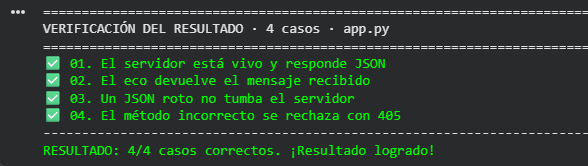